In [31]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


## 1. Problem

For this Kaggle project, airlines want to know which parts of the travel experience actually drive passenger satisfaction, to see what they should focus their spending on. Each row of the dataset represents a passenger's flight. There are personal features such as (age, gender, loyalty status)  and 14 service ratings on a 0-5 scale (wifi, seat comfort, boarding, food, cleanliness, and so on).

The response variable is *satisfaction*, a binary label indicating either satisfied or neutral/dissatisfied. 1 = satisfied, 0 = neutral/dissastified.


## 2. Data Exploration

In [32]:
# Load data
train = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

print("train:", train.shape)
print("test: ", test.shape)
train.head()

train: (699635, 23)
test:  (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [33]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [34]:
# response distribution
def to_binary(s):
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int)
    return (s.astype(str).str.strip() == "satisfied").astype(int)


print("raw dtype of the target:", train["satisfaction"].dtype)
print(train["satisfaction"].value_counts())

sat = to_binary(train["satisfaction"])
print()
print("proportion satisfied:", round(sat.mean(), 4))

raw dtype of the target: bool
satisfaction
False    389296
True     310339
Name: count, dtype: int64

proportion satisfied: 0.4436


In [35]:
# missing values
miss = train.isna().sum()
miss = miss[miss > 0]
print("columns with missing values in train:")
print(miss)
print()
print("as a percent:")
print((miss / len(train) * 100).round(3))
print()
print("test missing:")
print(test.isna().sum()[test.isna().sum() > 0])

columns with missing values in train:
Arrival Delay in Minutes    292
dtype: int64

as a percent:
Arrival Delay in Minutes    0.042
dtype: float64

test missing:
Arrival Delay in Minutes    130
dtype: int64


In [36]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,699635.0,349817.000000,201967.372129,0.0,174908.5,349817.0,524725.5,699634.0
Age,699635.0,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,3.156210,1.475390,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,2.813240,1.329550,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,3.568950,1.275333,0.0,3.0,4.0,5.0,5.0


In [37]:
ratings = [
    "Inflight wifi service", "Departure/Arrival time convenient",
    "Ease of Online booking", "Gate location", "Food and drink",
    "Online boarding", "Seat comfort", "Inflight entertainment",
    "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness",
]
ratings = [c for c in ratings if c in train.columns]

# these are rated 0-5, but 0 means "not applicable" rather than "terrible"
for c in ratings[:4]:
    print(c, "->", sorted(train[c].dropna().unique()))
print()
print("percent of 0 ratings in each column:")
print((train[ratings] == 0).mean().round(4).sort_values(ascending=False))

Inflight wifi service -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Departure/Arrival time convenient -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Ease of Online booking -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Gate location -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

percent of 0 ratings in each column:
Departure/Arrival time convenient    0.0368
Ease of Online booking               0.0230
Inflight wifi service                0.0187
Online boarding                      0.0131
Leg room service                     0.0024
Gate location                        0.0021
Inflight entertainment               0.0015
Food and drink                       0.0014
Cleanliness                          0.0014
Checkin service                      0.0013
Seat comfort                         0.0012
On-board service                     0.0011
Baggage handl

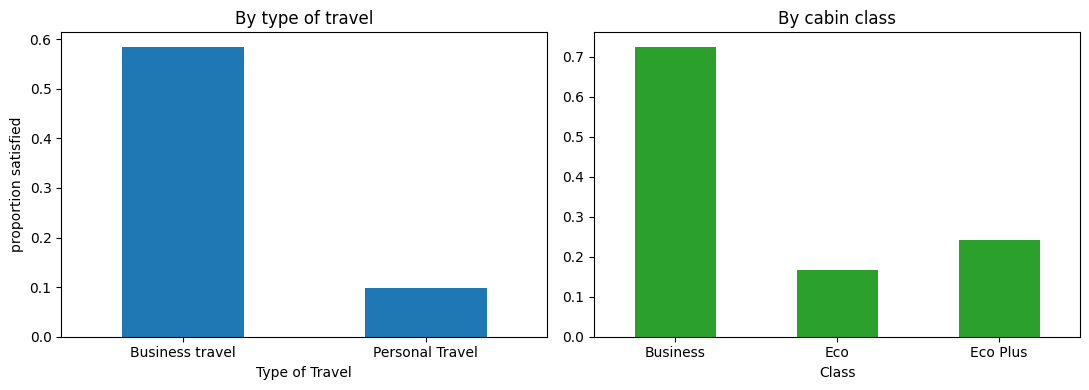

In [38]:
# notable relationship 1: satisfaction by travel type and class
eda = train.copy()
eda["satisfied"] = sat

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

eda.groupby("Type of Travel")["satisfied"].mean().plot(
    kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_ylabel("proportion satisfied")
axes[0].set_title("By type of travel")
axes[0].tick_params(axis="x", rotation=0)

eda.groupby("Class")["satisfied"].mean().plot(
    kind="bar", ax=axes[1], color="tab:green")
axes[1].set_title("By cabin class")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

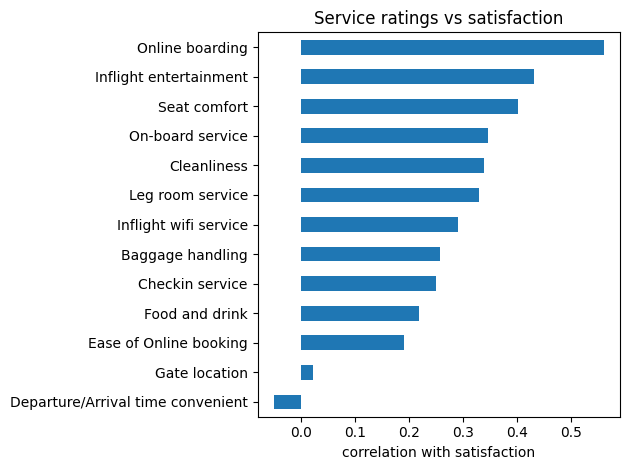

Departure/Arrival time convenient   -0.049
Gate location                        0.023
Ease of Online booking               0.191
Food and drink                       0.218
Checkin service                      0.250
Baggage handling                     0.258
Inflight wifi service                0.291
Leg room service                     0.330
Cleanliness                          0.339
On-board service                     0.347
Seat comfort                         0.401
Inflight entertainment               0.431
Online boarding                      0.560
dtype: float64


In [39]:
# ratings correlation with satisfaction
corrs = train[ratings].corrwith(eda["satisfied"]).sort_values()

corrs.plot(kind="barh")
plt.xlabel("correlation with satisfaction")
plt.title("Service ratings vs satisfaction")
plt.tight_layout()
plt.show()

print(corrs.round(3))

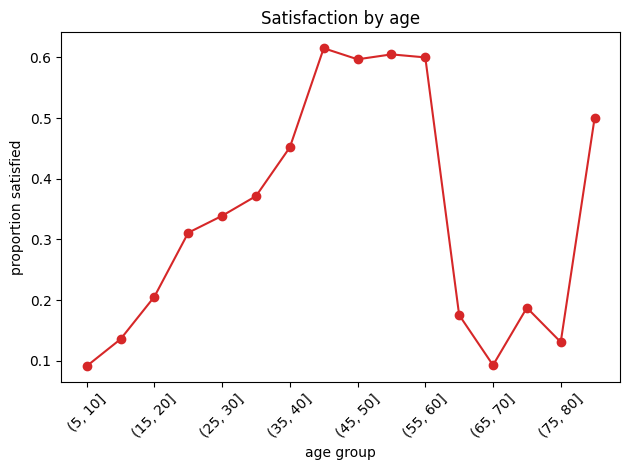

In [40]:
# notable relationship 2: satisfaction by age
age_bins = pd.cut(eda["Age"], bins=range(0, 90, 5))
eda.groupby(age_bins, observed=True)["satisfied"].mean().plot(
    marker="o", color="tab:red")
plt.ylabel("proportion satisfied")
plt.xlabel("age group")
plt.title("Satisfaction by age")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Data Preperation
Things to handle
- target variable: ensure 0/1 like competition files
- missing values: only `Arrival Delay in Minutes` is missing. fill in with median. These likely exist due to cancelled or untracked flights.
- categorical predictors: one-hot encode `Gender`, `Customer Type`, `Type of Travel`, `Class`
- Feature Engineering 

In [41]:
# target
y = to_binary(train["satisfaction"])   # defined in section 2
print(y.value_counts())

satisfaction
0    389296
1    310339
Name: count, dtype: int64


In [42]:
# feature engineering
def make_features(df):
    df = df.copy()

    # summaries across the service ratings
    if ratings:
        r = df[ratings]
        df["rate_mean"] = r.mean(axis=1)
        df["rate_std"] = r.std(axis=1)
        df["rate_min"] = r.min(axis=1)
        df["rate_max"] = r.max(axis=1)

        # 0 means "not applicable", so count those separately from bad scores
        df["n_zero_ratings"] = (r == 0).sum(axis=1)
        df["n_low_ratings"] = r.isin([1, 2]).sum(axis=1)
        df["n_high_ratings"] = (r >= 4).sum(axis=1)

    dep = "Departure Delay in Minutes"
    arr = "Arrival Delay in Minutes"

    if dep in df.columns and arr in df.columns:
        df["arr_delay_missing"] = df[arr].isna().astype(int)
        df["delay_diff"] = df[arr] - df[dep]        # time made up in the air
        df["delay_total"] = df[arr].fillna(0) + df[dep]
        df["log_dep_delay"] = np.log1p(df[dep].clip(lower=0))
        df["log_arr_delay"] = np.log1p(df[arr].clip(lower=0))
        df["on_time"] = (df["delay_total"] == 0).astype(int)

    if "Flight Distance" in df.columns:
        df["log_distance"] = np.log1p(df["Flight Distance"])
        if arr in df.columns:
            df["delay_per_km"] = df[arr] / df["Flight Distance"].clip(lower=1)

    return df


drop_cols = [c for c in ["id", "satisfaction"] if c in train.columns]
X = make_features(train.drop(columns=drop_cols))
X_test = make_features(test.drop(columns=["id"]))

test_ids = test["id"].values

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
print("features after engineering:", X.shape[1])
X.head()

features after engineering: 36


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,rate_mean,rate_std,rate_min,rate_max,n_zero_ratings,n_low_ratings,n_high_ratings,arr_delay_missing,delay_diff,delay_total,log_dep_delay,log_arr_delay,on_time,log_distance,delay_per_km
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,2.846154,1.344504,1,4,0,4,6,0,0.0,0.0,0.000000,0.0,1,6.543912,0.0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,4.615385,0.650444,3,5,0,0,12,0,0.0,0.0,0.000000,0.0,1,6.480045,0.0
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,3.461538,0.877058,2,5,0,1,5,0,0.0,0.0,0.000000,0.0,1,7.224025,0.0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,3.461538,0.776250,3,5,0,0,4,0,0.0,0.0,0.000000,0.0,1,7.388328,0.0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,4.153846,0.898717,3,5,0,0,9,0,-5.0,5.0,1.791759,0.0,0,6.177944,0.0


In [43]:
# one-hot encode categoricals
cat_cols = list(X.select_dtypes(include=["object", "string", "category"]).columns)
print("categorical columns:", cat_cols)
for c in cat_cols:
    print(" ", c, "->", list(X[c].unique()))

n_train = len(X)   # save this BEFORE reassigning X below

# encode train and test together so the columns line up
both = pd.concat([X, X_test], axis=0, ignore_index=True)
# dtype=int so the new columns are 0/1 numbers, not True/False
both = pd.get_dummies(both, columns=cat_cols, drop_first=True, dtype=int)

X = both.iloc[:n_train].reset_index(drop=True)
X_test = both.iloc[n_train:].reset_index(drop=True)

print()
print("final shape:", X.shape)

categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
  Gender -> ['Female', 'Male']
  Customer Type -> ['Loyal Customer', 'disloyal Customer']
  Type of Travel -> ['Personal Travel', 'Business travel']
  Class -> ['Eco', 'Business', 'Eco Plus']

final shape: (699635, 37)


In [44]:
# median-filled copy for log reg., cant take NaNs
med = X.median()
X_filled = X.fillna(med)
X_test_filled = X_test.fillna(med)   # fill test with TRAIN medians, not its own

print("NaNs left in X_filled:", int(X_filled.isna().sum().sum()))
print("NaNs left in X_test_filled:", int(X_test_filled.isna().sum().sum()))

NaNs left in X_filled: 0
NaNs left in X_test_filled: 0


#### Validation Procedure

Evaluate models using a 5 k-fold CV approach on the training data. AUC computed on the out of fold predictions. 

In [45]:
def cv_auc(model, X, y, X_test=None, n_splits=5, label=""):
    # 5-fold stratified CV. Returns out-of-fold preds and averaged test preds.
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test)) if X_test is not None else None

    for fold, (tr, va) in enumerate(skf.split(X, y), 1):
        model.fit(X.iloc[tr], y.iloc[tr])
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
        if X_test is not None:
            test_pred += model.predict_proba(X_test)[:, 1] / n_splits
        print(f"  fold {fold} AUC = {roc_auc_score(y.iloc[va], oof[va]):.5f}")

    score = roc_auc_score(y, oof)
    print(f"{label} overall CV AUC = {score:.5f}")
    return oof, test_pred, score


results = {}   # model name -> CV AUC
oof_preds = {} # model name -> out-of-fold predictions

# 4. Base Model: logistic regression

In [46]:
SEED = 42

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=SEED)
)

print("Logistic regression")
oof_lr, test_lr, auc_lr = cv_auc(logreg, X_filled, y, X_test_filled, label="LogReg")

results["Logistic Regression"] = auc_lr
oof_preds["Logistic Regression"] = oof_lr

Logistic regression
  fold 1 AUC = 0.94220
  fold 2 AUC = 0.94065
  fold 3 AUC = 0.94153
  fold 4 AUC = 0.94112
  fold 5 AUC = 0.94123
LogReg overall CV AUC = 0.94135


# 5. Additional Models

In [47]:
# random forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=10,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED,
)

print("Random forest")
oof_rf, test_rf, auc_rf = cv_auc(rf, X_filled, y, X_test_filled, label="RandomForest")

results["Random Forest"] = auc_rf
oof_preds["Random Forest"] = oof_rf

Random forest
  fold 1 AUC = 0.95643
  fold 2 AUC = 0.95508
  fold 3 AUC = 0.95640
  fold 4 AUC = 0.95654
  fold 5 AUC = 0.95625
RandomForest overall CV AUC = 0.95614


In [48]:
# histogram gradient boostingfrom sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(
    max_iter=600,
    learning_rate=0.06,
    max_leaf_nodes=63,
    min_samples_leaf=40,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=50,
    random_state=SEED,
)

print("Histogram gradient boosting")
oof_hgb, test_hgb, auc_hgb = cv_auc(hgb, X, y, X_test, label="HistGB")

results["Hist Gradient Boosting"] = auc_hgb
oof_preds["Hist Gradient Boosting"] = oof_hgb

Histogram gradient boosting
  fold 1 AUC = 0.95819
  fold 2 AUC = 0.95702
  fold 3 AUC = 0.95869
  fold 4 AUC = 0.95807
  fold 5 AUC = 0.95841
HistGB overall CV AUC = 0.95806


In [49]:
# LightGBM
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=96,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=SEED,
    verbose=-1,
)

print("LightGBM")
oof_lgb, test_lgb, auc_lgb = cv_auc(lgbm, X, y, X_test, label="LightGBM")

results["LightGBM"] = auc_lgb
oof_preds["LightGBM"] = oof_lgb

LightGBM
  fold 1 AUC = 0.95867
  fold 2 AUC = 0.95748
  fold 3 AUC = 0.95901
  fold 4 AUC = 0.95844
  fold 5 AUC = 0.95878
LightGBM overall CV AUC = 0.95847


# 6. Model Comparison

In [50]:
# comparison table
table = pd.Series(results).sort_values(ascending=False).to_frame("CV AUC")
table["vs baseline"] = (table["CV AUC"] - results["Logistic Regression"]).round(5)
print(table.round(5))

                         CV AUC  vs baseline
LightGBM                0.95847      0.01712
Hist Gradient Boosting  0.95806      0.01671
Random Forest           0.95614      0.01479
Logistic Regression     0.94135      0.00000


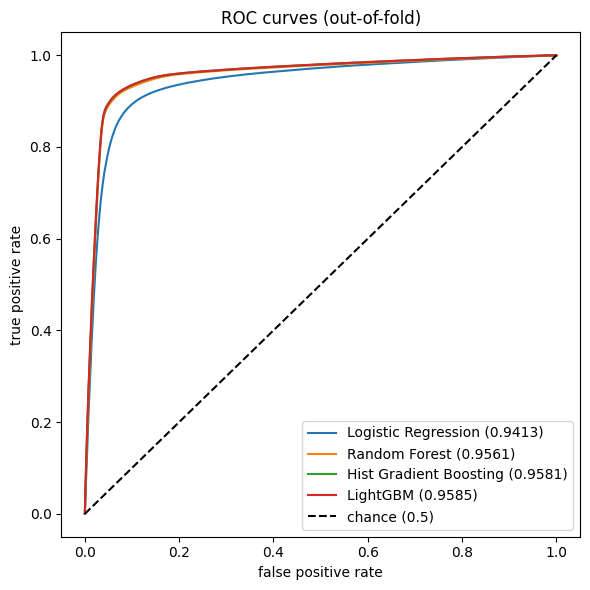

In [51]:
# ROC curve
plt.figure(figsize=(6, 6))
for name, p in oof_preds.items():
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f"{name} ({results[name]:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="chance (0.5)")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC curves (out-of-fold)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [52]:
# improve score by averaging two best models?
from scipy.stats import rankdata

# average the ranks rather than the raw probabilities, since AUC only cares
# about ordering and the two models are calibrated differently
blend_oof = (rankdata(oof_lgb) + rankdata(oof_hgb)) / (2 * len(y))
blend_auc = roc_auc_score(y, blend_oof)

print(f"LightGBM alone       {auc_lgb:.5f}")
print(f"HistGB alone         {auc_hgb:.5f}")
print(f"rank-average blend   {blend_auc:.5f}")

results["Blend (LGBM + HistGB)"] = blend_auc
oof_preds["Blend (LGBM + HistGB)"] = blend_oof

LightGBM alone       0.95847
HistGB alone         0.95806
rank-average blend   0.95856


In [53]:
if blend_auc > auc_lgb:
    final_test_pred = (rankdata(test_lgb) + rankdata(test_hgb)) / (2 * len(test_lgb))
    final_name = "Blend (LGBM + HistGB)"
    final_cv = blend_auc
else:
    final_test_pred = test_lgb
    final_name = "LightGBM"
    final_cv = auc_lgb

print("final model:", final_name)
print("final CV AUC:", round(final_cv, 5))

final model: Blend (LGBM + HistGB)
final CV AUC: 0.95856


# 7. Model Interpretation

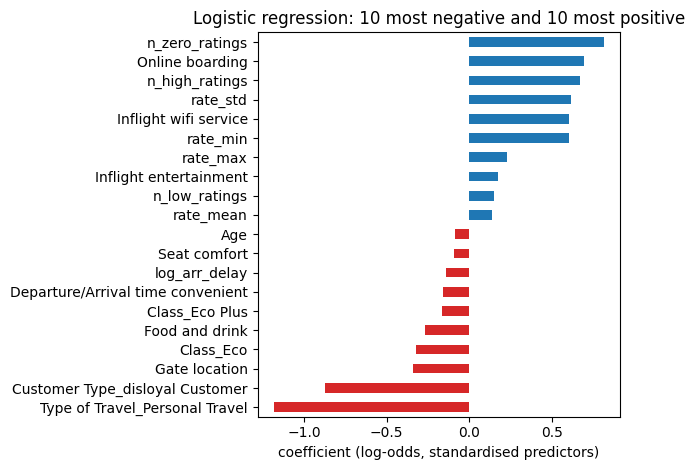

In [54]:
# logistic regression ranked feature importance
logreg.fit(X_filled, y)
coefs = pd.Series(
    logreg.named_steps["logisticregression"].coef_[0], index=X_filled.columns
).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot(kind="barh", color=["tab:red"] * 10 + ["tab:blue"] * 10)
plt.xlabel("coefficient (log-odds, standardised predictors)")
plt.title("Logistic regression: 10 most negative and 10 most positive")
plt.tight_layout()
plt.show()

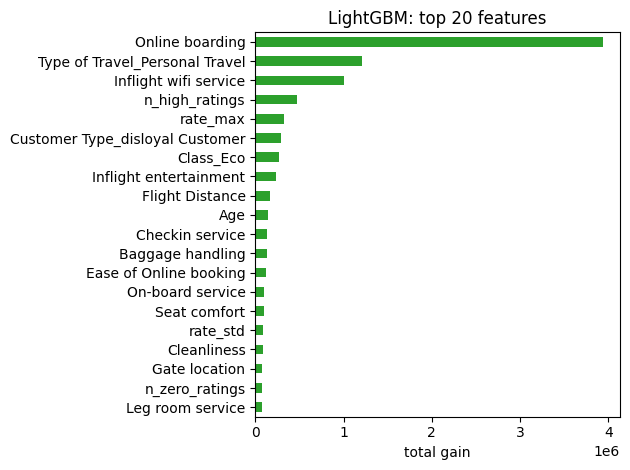

Online boarding                    3934943.0
Type of Travel_Personal Travel     1210878.0
Inflight wifi service              1004967.0
n_high_ratings                      472844.0
rate_max                            327043.0
Customer Type_disloyal Customer     292747.0
Class_Eco                           266801.0
Inflight entertainment              233110.0
Flight Distance                     168416.0
Age                                 140339.0
Checkin service                     135434.0
Baggage handling                    133482.0
Ease of Online booking              127473.0
On-board service                     98698.0
Seat comfort                         98235.0
dtype: float64


In [55]:
# lightGBM ranked feature importance
lgbm.fit(X, y)
imp = pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"), index=X.columns
).sort_values(ascending=False)

imp.head(20)[::-1].plot(kind="barh", color="tab:green")
plt.xlabel("total gain")
plt.title("LightGBM: top 20 features")
plt.tight_layout()
plt.show()

print(imp.head(15).round(0))

# 8. Kaggle Submission

In [56]:
submission = pd.DataFrame({
    "id": test_ids,
    "satisfaction": final_test_pred,
})

submission.to_csv("submission.csv", index=False)

print("rows:", len(submission))
print("duplicate ids:", submission["id"].duplicated().sum())
print("prediction range: %.4f to %.4f" % (
    submission["satisfaction"].min(), submission["satisfaction"].max()))
submission.head()

rows: 299844
duplicate ids: 0
prediction range: 0.0000 to 1.0000


,id,satisfaction
0,699635,0.519148
1,699636,0.609932
2,699637,0.634870
3,699638,0.454870
4,699639,0.383394


# 9. Reflection

Overall, we thought our approach worked pretty well, especially using boosting and random forests to improve our predictions. These models worked better than logistic regression because they could pick up on more complicated relationships in the data. Logistic regression didn't perform as well and had a lower AUC score than the other models we tried. We also noticed that using more complicated models didn't always mean better results. If we were to keep working on this project, we would try bagging, which we just learned about, to see how it compares to random forests and boosting. We could also try adjusting more of the model parameters to see if we could get a better prediction accuracy.
